In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os, torch, torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

root = "/kaggle/input/datasets/mohitsingh1804/plantvillage/PlantVillage"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]
size = 128

train_tf = transforms.Compose([transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(), transforms.ToTensor(),
    transforms.Normalize(mean, std)])
val_tf = transforms.Compose([transforms.Resize((size, size)),
    transforms.ToTensor(), transforms.Normalize(mean, std)])

train_ds = datasets.ImageFolder(root + "/train", transform=train_tf)
val_ds   = datasets.ImageFolder(root + "/val",   transform=val_tf)
print("Classes:", len(train_ds.classes), "| Train:", len(train_ds), "| Val:", len(val_ds))

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True,  num_workers=4, pin_memory=True)
val_dl   = DataLoader(val_ds,   batch_size=64, shuffle=False, num_workers=4, pin_memory=True)

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, len(train_ds.classes))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

Device: cuda
Classes: 38 | Train: 43444 | Val: 10861
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s] 


In [4]:
print(os.listdir("/kaggle/working"))

['.virtual_documents']


In [5]:
for root_, dirs, files in os.walk("/kaggle/input"):
    for f in files:
        if f.endswith(".pth"):
            print(os.path.join(root_, f))

/kaggle/input/datasets/adieltweneboahkoduah/plant-resnet18/plant_resnet18.pth


In [6]:
ckpt = torch.load("/kaggle/input/datasets/adieltweneboahkoduah/plant-resnet18/plant_resnet18.pth", map_location=device)
model.load_state_dict(ckpt["model"])
model.eval()
print("Loaded. Classes:", len(ckpt["classes"]))

Loaded. Classes: 38


In [7]:
import numpy as np
preds, truth = [], []
with torch.no_grad():
    for x, y in val_dl:
        out = model(x.to(device))
        preds += out.argmax(1).cpu().tolist()
        truth += y.tolist()
preds, truth = np.array(preds), np.array(truth)
print("Overall val accuracy:", (preds == truth).mean())

Overall val accuracy: 0.9059939232114906


In [8]:
from sklearn.metrics import classification_report
print(classification_report(truth, preds, target_names=train_ds.classes, digits=3))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.843     0.849     0.846       126
                                 Apple___Black_rot      0.955     0.856     0.903       125
                          Apple___Cedar_apple_rust      0.949     0.673     0.787        55
                                   Apple___healthy      0.939     0.939     0.939       329
                               Blueberry___healthy      0.979     0.953     0.966       300
          Cherry_(including_sour)___Powdery_mildew      0.902     0.967     0.933       210
                 Cherry_(including_sour)___healthy      0.942     0.953     0.947       170
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.880     0.641     0.742       103
                       Corn_(maize)___Common_rust_      0.991     0.967     0.979       239
               Corn_(maize)___Northern_Leaf_Blight      0.815     0.939     0.8

In [9]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(truth, preds)
np.fill_diagonal(cm, 0)
pairs = [(cm[i, j], i, j) for i in range(len(cm)) for j in range(len(cm)) if cm[i, j] > 0]
for n, i, j in sorted(pairs, reverse=True)[:10]:
    print(f"{n:4d}  true: {train_ds.classes[i]}  ->  predicted: {train_ds.classes[j]}")

  45  true: Tomato___Target_Spot  ->  predicted: Tomato___Spider_mites Two-spotted_spider_mite
  33  true: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot  ->  predicted: Corn_(maize)___Northern_Leaf_Blight
  31  true: Grape___Black_rot  ->  predicted: Grape___Esca_(Black_Measles)
  24  true: Tomato___Bacterial_spot  ->  predicted: Tomato___Early_blight
  23  true: Tomato___Tomato_Yellow_Leaf_Curl_Virus  ->  predicted: Tomato___Spider_mites Two-spotted_spider_mite
  23  true: Tomato___Leaf_Mold  ->  predicted: Tomato___Septoria_leaf_spot
  22  true: Tomato___healthy  ->  predicted: Tomato___Target_Spot
  21  true: Tomato___Bacterial_spot  ->  predicted: Tomato___Septoria_leaf_spot
  18  true: Tomato___Late_blight  ->  predicted: Tomato___Early_blight
  16  true: Tomato___Spider_mites Two-spotted_spider_mite  ->  predicted: Tomato___Target_Spot


In [31]:
for p in model.layer4.parameters():
    p.requires_grad = True

optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(),     "lr": 1e-3},
])

In [32]:
print(device, len(train_ds), callable(run_epoch))

NameError: name 'run_epoch' is not defined

In [33]:
ckpt = torch.load(
    "/kaggle/input/datasets/adieltweneboahkoduah/plant-resnet18/plant_resnet18.pth",
    map_location=device,
)
model.load_state_dict(ckpt["model"])

<All keys matched successfully>

In [42]:
from tqdm.notebook import tqdm

def run_epoch(dl, train):
    model.train(train)
    total_loss, correct, n = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in tqdm(dl):
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

In [43]:
for p in model.layer4.parameters():
    p.requires_grad = True

optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(),     "lr": 1e-3},
])

In [44]:
for epoch in range(2):
    tl, ta = run_epoch(train_dl, True)
    vl, va = run_epoch(val_dl, False)
    print(f"Fine-tune epoch {epoch+1}: train {ta:.3f} | val {va:.3f}")
    torch.save({"model": model.state_dict(), "classes": train_ds.classes},
               "/kaggle/working/plant_resnet18_ft.pth")

  0%|          | 0/679 [00:00<?, ?it/s]

  0%|          | 0/170 [00:00<?, ?it/s]

Fine-tune epoch 1: train 0.955 | val 0.974


  0%|          | 0/679 [00:00<?, ?it/s]

  0%|          | 0/170 [00:00<?, ?it/s]

Fine-tune epoch 2: train 0.984 | val 0.976


In [45]:
from IPython.display import FileLink
FileLink("plant_resnet18_ft.pth")

/kaggle/working/plant_resnet18_ft.pth

In [46]:
model.eval()
preds, truth = [], []
with torch.no_grad():
    for x, y in val_dl:
        preds += model(x.to(device)).argmax(1).cpu().tolist()
        truth += y.tolist()
preds, truth = np.array(preds), np.array(truth)

from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(truth, preds, target_names=train_ds.classes, digits=3))

cm = confusion_matrix(truth, preds)
np.fill_diagonal(cm, 0)
pairs = [(cm[i, j], i, j) for i in range(len(cm)) for j in range(len(cm)) if cm[i, j] > 0]
for n, i, j in sorted(pairs, reverse=True)[:10]:
    print(f"{n:4d}  true: {train_ds.classes[i]}  ->  predicted: {train_ds.classes[j]}")

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.984     0.976     0.980       126
                                 Apple___Black_rot      0.992     1.000     0.996       125
                          Apple___Cedar_apple_rust      0.982     0.982     0.982        55
                                   Apple___healthy      0.994     0.991     0.992       329
                               Blueberry___healthy      0.997     0.997     0.997       300
          Cherry_(including_sour)___Powdery_mildew      1.000     0.990     0.995       210
                 Cherry_(including_sour)___healthy      1.000     0.994     0.997       170
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.681     0.951     0.794       103
                       Corn_(maize)___Common_rust_      0.996     0.996     0.996       239
               Corn_(maize)___Northern_Leaf_Blight      0.981     0.772     0.8

In [1]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    print(root, len(files))
    if root.count("/") > 5:
        break

/kaggle/input 0
/kaggle/input/datasets 0
/kaggle/input/datasets/mohitsingh1804 0
/kaggle/input/datasets/mohitsingh1804/plantvillage 0
/kaggle/input/datasets/mohitsingh1804/plantvillage/PlantVillage 0


In [2]:
import torch
print(torch.cuda.is_available())

True


In [3]:
import os

root = "/kaggle/input/datasets/mohitsingh1804/plantvillage/PlantVillage"
print(os.listdir(root))

['train', 'val']


In [4]:
base = root + "/train"

total = 0
for cls in sorted(os.listdir(base)):
    path = os.path.join(base, cls)
    if os.path.isdir(path):
        n = len(os.listdir(path))
        total += n
        print(f"{cls}: {n}")
print("Total train images:", total)

Apple___Apple_scab: 504
Apple___Black_rot: 496
Apple___Cedar_apple_rust: 220
Apple___healthy: 1316
Blueberry___healthy: 1202
Cherry_(including_sour)___Powdery_mildew: 842
Cherry_(including_sour)___healthy: 684
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 410
Corn_(maize)___Common_rust_: 953
Corn_(maize)___Northern_Leaf_Blight: 788
Corn_(maize)___healthy: 929
Grape___Black_rot: 944
Grape___Esca_(Black_Measles): 1107
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 861
Grape___healthy: 339
Orange___Haunglongbing_(Citrus_greening): 4405
Peach___Bacterial_spot: 1838
Peach___healthy: 288
Pepper,_bell___Bacterial_spot: 797
Pepper,_bell___healthy: 1183
Potato___Early_blight: 800
Potato___Late_blight: 800
Potato___healthy: 121
Raspberry___healthy: 297
Soybean___healthy: 4072
Squash___Powdery_mildew: 1468
Strawberry___Leaf_scorch: 887
Strawberry___healthy: 364
Tomato___Bacterial_spot: 1702
Tomato___Early_blight: 800
Tomato___Late_blight: 1527
Tomato___Leaf_Mold: 761
Tomato___Septoria_leaf_spo

In [5]:
base = root + "/val"

total = 0
for cls in sorted(os.listdir(base)):
    path = os.path.join(base, cls)
    if os.path.isdir(path):
        n = len(os.listdir(path))
        total += n
        print(f"{cls}: {n}")
print("Total train images:", total)

Apple___Apple_scab: 126
Apple___Black_rot: 125
Apple___Cedar_apple_rust: 55
Apple___healthy: 329
Blueberry___healthy: 300
Cherry_(including_sour)___Powdery_mildew: 210
Cherry_(including_sour)___healthy: 170
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 103
Corn_(maize)___Common_rust_: 239
Corn_(maize)___Northern_Leaf_Blight: 197
Corn_(maize)___healthy: 233
Grape___Black_rot: 236
Grape___Esca_(Black_Measles): 276
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 215
Grape___healthy: 84
Orange___Haunglongbing_(Citrus_greening): 1102
Peach___Bacterial_spot: 459
Peach___healthy: 72
Pepper,_bell___Bacterial_spot: 200
Pepper,_bell___healthy: 295
Potato___Early_blight: 200
Potato___Late_blight: 200
Potato___healthy: 31
Raspberry___healthy: 74
Soybean___healthy: 1018
Squash___Powdery_mildew: 367
Strawberry___Leaf_scorch: 222
Strawberry___healthy: 92
Tomato___Bacterial_spot: 425
Tomato___Early_blight: 200
Tomato___Late_blight: 382
Tomato___Leaf_Mold: 191
Tomato___Septoria_leaf_spot: 354
Tomato_

In [6]:
import random
cls = sorted(os.listdir(root + "/train"))[0]
files = os.listdir(root + "/train/" + cls)
print(cls)
print(random.sample(files, 10))

Apple___Apple_scab
['d66bf6da-1199-4f2b-9776-8cbc4529b268___FREC_Scab 3157.JPG', 'f777466d-15ee-4269-b90c-0d64bd099c0f___FREC_Scab 3409.JPG', 'd480dbfb-ce18-40cf-a183-9bc52ec9195d___FREC_Scab 3303.JPG', 'f3303560-12ce-4e37-b62c-bfb5aad8aa0d___FREC_Scab 3332.JPG', 'cd7bc55c-1c47-4af7-9875-f29147d54115___FREC_Scab 3471.JPG', '4bb38e05-1d5a-40c6-8638-10db134db682___FREC_Scab 3390.JPG', '55cd6283-a5b1-47e9-b061-c7692c8ba781___FREC_Scab 3460.JPG', 'd730c2c9-ac5f-4c4e-b568-2f3e8b43b1a9___FREC_Scab 3074.JPG', '78f8b36a-5126-4105-9699-39387015452f___FREC_Scab 2983.JPG', '2c7ca7c8-1a6c-4811-b9b0-b054c11a5397___FREC_Scab 3260.JPG']


In [3]:
import hashlib

def file_hash(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

def hashes(split):
    s = set()
    for cls in os.listdir(f"{root}/{split}"):
        d = f"{root}/{split}/{cls}"
        if os.path.isdir(d):
            for fn in os.listdir(d):
                s.add(file_hash(f"{d}/{fn}"))
    return s

tr, va = hashes("train"), hashes("val")
print("Train:", len(tr), "Val:", len(va), "Overlap:", len(tr & va))

NameError: name 'os' is not defined

In [4]:
import random

def all_files(split):
    out = []
    for cls in os.listdir(f"{root}/{split}"):
        d = f"{root}/{split}/{cls}"
        if os.path.isdir(d):
            out += [f"{d}/{fn}" for fn in os.listdir(d)]
    return out

val_files = all_files("val")
train_files = all_files("train")
print("Train:", len(train_files), "Val:", len(val_files))

# Cheap first pass: compare file sizes in bytes (instant)
train_sizes = {}
for p in train_files:
    train_sizes.setdefault(os.path.getsize(p), []).append(p)

sample = random.sample(val_files, min(300, len(val_files)))
candidates = [p for p in sample if os.path.getsize(p) in train_sizes]
print("Sampled val files with a same-size file in train:", len(candidates), "of", len(sample))

NameError: name 'os' is not defined

In [5]:
import os
import random

def all_files(split):
    out = []
    for cls in os.listdir(f"{root}/{split}"):
        d = f"{root}/{split}/{cls}"
        if os.path.isdir(d):
            out += [f"{d}/{fn}" for fn in os.listdir(d)]
    return out

val_files = all_files("val")
train_files = all_files("train")
print("Train:", len(train_files), "Val:", len(val_files))

# Cheap first pass: compare file sizes in bytes (instant)
train_sizes = {}
for p in train_files:
    train_sizes.setdefault(os.path.getsize(p), []).append(p)

sample = random.sample(val_files, min(300, len(val_files)))
candidates = [p for p in sample if os.path.getsize(p) in train_sizes]
print("Sampled val files with a same-size file in train:", len(candidates), "of", len(sample))

NameError: name 'root' is not defined

In [6]:
import os
import random
root="/kaggle/input/PlantVillage"
def all_files(split):
    out = []
    for cls in os.listdir(f"{root}/{split}"):
        d = f"{root}/{split}/{cls}"
        if os.path.isdir(d):
            out += [f"{d}/{fn}" for fn in os.listdir(d)]
    return out

val_files = all_files("val")
train_files = all_files("train")
print("Train:", len(train_files), "Val:", len(val_files))

# Cheap first pass: compare file sizes in bytes (instant)
train_sizes = {}
for p in train_files:
    train_sizes.setdefault(os.path.getsize(p), []).append(p)

sample = random.sample(val_files, min(300, len(val_files)))
candidates = [p for p in sample if os.path.getsize(p) in train_sizes]
print("Sampled val files with a same-size file in train:", len(candidates), "of", len(sample))

FileNotFoundError: [Errno 2] No such file or directory: '/kaggle/input/PlantVillage/val'

In [10]:
!ls /kaggle/input
!ls /kaggle/input/*

datasets
mohitsingh1804


In [11]:
!ls /kaggle/input/datasets/mohitsingh1804
!ls /kaggle/input/datasets/mohitsingh1804/*

plantvillage
PlantVillage


In [12]:
!ls /kaggle/input/datasets/mohitsingh1804/plantvillage/PlantVillage

train  val


In [16]:
import random
import os
root="/kaggle/input/datasets/mohitsingh1804/plantvillage/PlantVillage"

def all_files(split):
    out = []
    for cls in os.listdir(f"{root}/{split}"):
        d = f"{root}/{split}/{cls}"
        if os.path.isdir(d):
            out += [f"{d}/{fn}" for fn in os.listdir(d)]
    return out

val_files = all_files("val")
train_files = all_files("train")
print("Train:", len(train_files), "Val:", len(val_files))

# Cheap first pass: compare file sizes in bytes (instant)
train_sizes = {}
for p in train_files:
    train_sizes.setdefault(os.path.getsize(p), []).append(p)

sample = random.sample(val_files, min(300, len(val_files)))
candidates = [p for p in sample if os.path.getsize(p) in train_sizes]
print("Sampled val files with a same-size file in train:", len(candidates), "of", len(sample))

Train: 43444 Val: 10861
Sampled val files with a same-size file in train: 265 of 300


In [17]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

mean = [0.485, 0.456, 0.406]   # standard ImageNet values,
std  = [0.229, 0.224, 0.225]   # needed for a pretrained model

train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

train_ds = datasets.ImageFolder(root + "/train", transform=train_tf)
val_ds   = datasets.ImageFolder(root + "/val",   transform=val_tf)

print("Classes:", len(train_ds.classes))
print(train_ds.classes)
print("Train:", len(train_ds), "Val:", len(val_ds))
print("Same classes in both:", train_ds.classes == val_ds.classes)

Classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato

In [22]:
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=2)
val_dl   = DataLoader(val_ds,   batch_size=32, shuffle=False, num_workers=2)

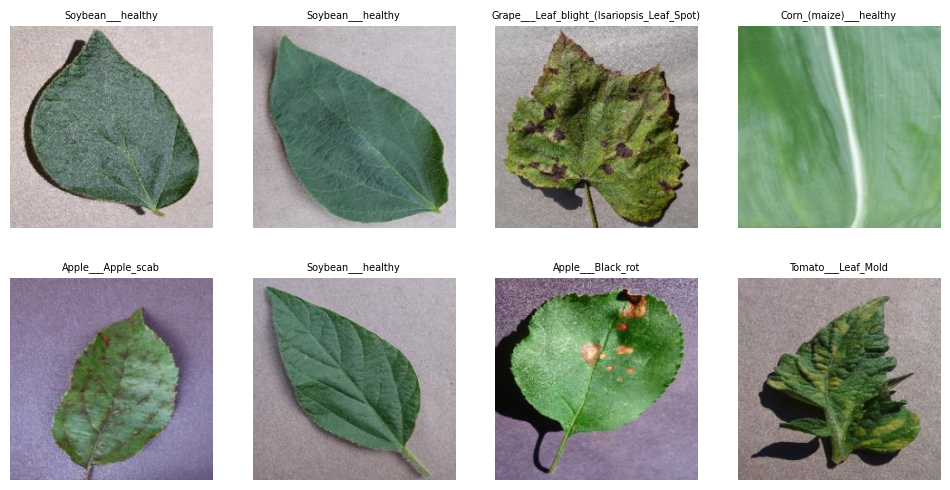

In [23]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_dl))
inv = images * torch.tensor(std).view(1,3,1,1) + torch.tensor(mean).view(1,3,1,1)

plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(inv[i].permute(1, 2, 0).clamp(0, 1))
    plt.title(train_ds.classes[labels[i]], fontsize=7)
    plt.axis("off")
plt.show()

In [24]:
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for p in model.parameters():       # freeze the pretrained layers
    p.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, len(train_ds.classes))  # new final layer
model = model.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 193MB/s]


In [33]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

In [11]:
def run_epoch(dl, train):
    model.train(train)
    total_loss, correct, n = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

for epoch in range(3):
    tl, ta = run_epoch(train_dl, True)
    vl, va = run_epoch(val_dl, False)
    print(f"Epoch {epoch+1}: train acc {ta:.3f} | val acc {va:.3f} | val loss {vl:.3f}")

NameError: name 'train_dl' is not defined

In [12]:
import os, torch, torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

root = "/kaggle/input/datasets/mohitsingh1804/plantvillage/PlantVillage"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]
size = 128

train_tf = transforms.Compose([transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(), transforms.ToTensor(),
    transforms.Normalize(mean, std)])
val_tf = transforms.Compose([transforms.Resize((size, size)),
    transforms.ToTensor(), transforms.Normalize(mean, std)])

train_ds = datasets.ImageFolder(root + "/train", transform=train_tf)
val_ds   = datasets.ImageFolder(root + "/val",   transform=val_tf)
print("Classes:", len(train_ds.classes), "| Train:", len(train_ds), "| Val:", len(val_ds))

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True,  num_workers=4, pin_memory=True)
val_dl   = DataLoader(val_ds,   batch_size=64, shuffle=False, num_workers=4, pin_memory=True)

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, len(train_ds.classes))
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

Device: cuda
Classes: 38 | Train: 43444 | Val: 10861
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 186MB/s]


In [13]:
from tqdm.notebook import tqdm

def run_epoch(dl, train):
    model.train(train)
    total_loss, correct, n = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in tqdm(dl):
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

for epoch in range(1):
    tl, ta = run_epoch(train_dl, True)
    vl, va = run_epoch(val_dl, False)
    print(f"Epoch {epoch+1}: train acc {ta:.3f} | val acc {va:.3f} | val loss {vl:.3f}")

  0%|          | 0/679 [00:00<?, ?it/s]

  0%|          | 0/170 [00:00<?, ?it/s]

Epoch 1: train acc 0.827 | val acc 0.906 | val loss 0.333


In [25]:
torch.save({"model": model.state_dict(), "classes": train_ds.classes},
           "/kaggle/working/plant_resnet18.pth")

In [27]:
import numpy as np
model.eval()
preds, truth = [], []
with torch.no_grad():
    for x, y in val_dl:
        out = model(x.to(device))
        preds += out.argmax(1).cpu().tolist()
        truth += y.tolist()
preds, truth = np.array(preds), np.array(truth)
print("Overall val accuracy:", (preds == truth).mean())

Overall val accuracy: 0.9059939232114906


In [28]:
from sklearn.metrics import classification_report
print(classification_report(truth, preds, target_names=train_ds.classes, digits=3))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.843     0.849     0.846       126
                                 Apple___Black_rot      0.955     0.856     0.903       125
                          Apple___Cedar_apple_rust      0.949     0.673     0.787        55
                                   Apple___healthy      0.939     0.939     0.939       329
                               Blueberry___healthy      0.979     0.953     0.966       300
          Cherry_(including_sour)___Powdery_mildew      0.902     0.967     0.933       210
                 Cherry_(including_sour)___healthy      0.942     0.953     0.947       170
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.880     0.641     0.742       103
                       Corn_(maize)___Common_rust_      0.991     0.967     0.979       239
               Corn_(maize)___Northern_Leaf_Blight      0.815     0.939     0.8

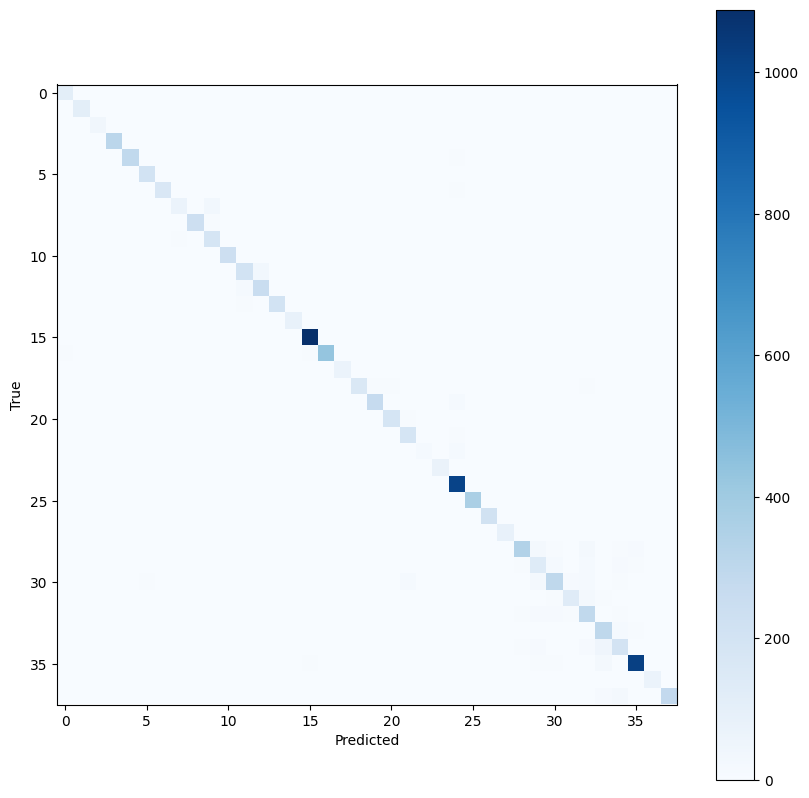

In [29]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
cm = confusion_matrix(truth, preds)
plt.figure(figsize=(10, 10))
plt.imshow(cm, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("True")
plt.colorbar(); plt.show()

In [31]:
from IPython.display import FileLink
FileLink("plant_resnet18.pth", result_html_prefix="Download: ")

/kaggle/working/plant_resnet18.pth

In [37]:
import time
t = time.time()
for i, (x, y) in enumerate(train_dl):
    if i == 20: break
print("20 batches:", round(time.time() - t, 1), "seconds")
print("Estimated full epoch:", round((time.time() - t) / 20 * len(train_dl) / 60, 1), "minutes")

20 batches: 11.7 seconds
Estimated full epoch: 13.2 minutes


In [ ]:
def run_epoch(dl, train):
    model.train(train)
    total_loss, correct, n = 0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

for epoch in range(3):
    tl, ta = run_epoch(train_dl, True)
    vl, va = run_epoch(val_dl, False)
    print(f"Epoch {epoch+1}: train acc {ta:.3f} | val acc {va:.3f} | val loss {vl:.3f}")